# R3 · Gene-set search accuracy (Fig 4)

For every held-out tile of the 8 sections and seeds 0–4, gene-set queries of |S| = 4 / 8 / 16 / 32 consecutive genes in
one block of the query's home niche are searched three ways:
* **Spindle** (SpindlePartial, g = 1)
* **padding** + Spindle-naive
* **imputation** + Spindle-naive

Each is graded against the exact gene-set distance d_B^S (Spindle-naive partial) with NX at 5 % of N and
Overlap(5 %, 5 % N). Code: `experiments/common/gene_set_accuracy.py` (workload and baselines in `gene_set.py`).

* **Prerequisites:** `R0_index_cache.ipynb`.
* **Writes** `results/gene_set/`:
  * `per_dataset/<key>/seed<k>.csv`: one row per (query, size, method)
  * `per_dataset/<key>/band_seed0.npz`: seed 0, |S| = 16, every query's d_B^S and Spindle's hits
  * `nx_seeds.csv`, `nx.csv`, `nx_size.csv`: summaries
  * `band/<key>.npz` and `band/typical.csv`: the typical |S| = 16 query
  * `storage.csv`: stored MB per dataset
  * `manifest.json`
* **Skips** a (dataset, seed) whose per-query CSV exists (`FORCE = True` redoes all).
* **Runtime / memory:** a few hours, one thread. Peak memory stays under 16 GB: only the held-out covariances are
  read, memory-mapped.

In [1]:
import gc
import sys
import time
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "datasets.yaml").exists())
sys.path.insert(0, str(ROOT / "experiments" / "common"))
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import data
import gene_set as gs
import gene_set_accuracy as gsa
import index_cache
import results_io as rio

TOPIC = "gene_set"
FORCE = False
assert index_cache.status().built.all() and index_cache.status().staged.all(), "run R0_index_cache.ipynb first"
print(data.stamp())

{'tag': 'method-v2', 'describe': 'method-v2-dirty', 'commit': '8040f91'}


## Search every held-out tile (per dataset and seed)

In [2]:
for key in data.indexed_keys():
    d = rio.per_dataset(TOPIC, key)
    for seed in data.SEEDS:
        f = d / f"seed{seed}.csv"
        if f.exists() and not FORCE:
            print(f"{key} seed {seed}: exists, skipped")
            continue
        t0 = time.perf_counter()
        df, band = gsa.run(key, seed)
        if band is not None:
            np.savez_compressed(d / f"band_seed{seed}.npz", **band)
        df.to_csv(f, index=False)
        m = df.groupby(["method", "size"]).NX5.mean().unstack()
        print(f"{key} seed {seed}: {df['query'].nunique()} queries in {time.perf_counter() - t0:.0f} s, "
              f"peak {rio.peak_rss_gb():.1f} GB; NX5 % by size:\n{(100 * m).round(2).to_string()}", flush=True)
        del df, band
        gc.collect()
for key in data.indexed_keys():
    d = rio.per_dataset(TOPIC, key)
    for seed in data.SEEDS:
        rio.register(TOPIC, d / f"seed{seed}.csv", "one row per (held-out query, |S|, method): NX5, Overlap, Spindle's "
                     "tiles returned / work / A_hat / radius, segments, imputation's predicted niche")
    rio.register(TOPIC, d / f"band_seed{data.EXAMPLE_SEED}.npz", "seed 0, |S| = 16: exact d_B^S of every query to every "
                 "index tile (D, float32) and the rows Spindle returned (found, offsets off), query test positions")

skin_melanoma seed 0: 93 queries in 11 s, peak 0.4 GB; NX5 % by size:
size                4      8      16      32
method                                      
imputation       51.36  49.82  44.14   32.04
padding          74.86  77.64  93.59  111.79
spindle_partial   6.34   7.33   9.05   11.10
skin_melanoma seed 1: 93 queries in 10 s, peak 0.4 GB; NX5 % by size:
size                4      8      16     32
method                                     
imputation       54.60  52.38  43.59  33.30
padding          72.16  75.81  85.50  97.98
spindle_partial   7.60   7.89   8.18   9.63
skin_melanoma seed 2: 93 queries in 10 s, peak 0.4 GB; NX5 % by size:
size                4      8      16      32
method                                      
imputation       56.61  56.55  47.53   33.56
padding          77.67  80.77  86.92  104.94
spindle_partial   6.33   6.51   9.46   10.88
skin_melanoma seed 3: 93 queries in 10 s, peak 0.4 GB; NX5 % by size:
size                4      8      16     32
method

## Summaries: NX5 and Overlap per dataset, seed and size

In [3]:
pq = pd.concat([pd.read_csv(rio.per_dataset(TOPIC, k) / f"seed{s}.csv") for k in data.indexed_keys()
                for s in data.SEEDS])
nx_seeds, nx, nx_size = gsa.nx_tables(pq)
rio.write_csv(nx_seeds, TOPIC, "nx_seeds.csv", "per (dataset, seed, method, size; 0 = pooled): mean NX5, Overlap over "
              "queries; Spindle short of 10 / 5 % N, median tiles returned and work; imputation home-niche share")
rio.write_csv(nx, TOPIC, "nx.csv", "per (dataset, method, size): mean and s.d. over seeds of nx_seeds")
rio.write_csv(nx_size, TOPIC, "nx_size.csv", "per (method, size): median over datasets per seed, mean and s.d. over "
              "seeds (Fig 4B, C)")
print("NX5 % per dataset, all sizes pooled (mean over seeds)")
display((100 * nx[nx["size"] == 0].pivot(index="key", columns="method", values="NX5")).round(2))
print("NX5 % per size, median over datasets (mean over seeds)")
display((100 * nx_size.pivot(index="size", columns="method", values="NX5")).round(2))

wrote results/gene_set/nx_seeds.csv: 600 rows
wrote results/gene_set/nx.csv: 120 rows
wrote results/gene_set/nx_size.csv: 15 rows
NX5 % per dataset, all sizes pooled (mean over seeds)


method,imputation,padding,spindle_partial
key,,,
brain_cancer,46.90,124.80,17.86
breast_cancer,48.75,82.36,11.27
kidney_nondiseased,63.85,80.50,17.61
lung_cancer,60.62,86.36,13.64
lymph_node,46.58,133.92,10.59
lymph_node_5k,59.03,79.71,31.45
pancreatic_cancer,53.95,96.08,10.43
skin_melanoma,45.61,84.31,8.75


NX5 % per size, median over datasets (mean over seeds)


method,imputation,padding,spindle_partial
size,,,
0,51.14,86.06,11.94
4,60.53,85.39,8.61
8,57.02,84.03,9.58
16,50.36,85.76,13.25
32,40.65,97.69,18.94


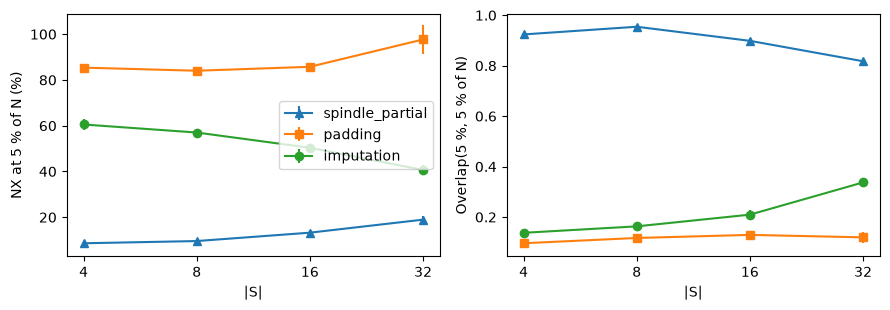

In [4]:
fig, axs = plt.subplots(1, 2, figsize=(9, 3.2))
for m, mk in (("spindle_partial", "^"), ("padding", "s"), ("imputation", "o")):
    s = nx_size[(nx_size.method == m) & (nx_size["size"] > 0)].sort_values("size")
    axs[0].errorbar(s["size"], 100 * s.NX5, yerr=100 * s.NX5_sd, fmt=f"-{mk}", label=m)
    axs[1].errorbar(s["size"], s.overlap5, yerr=s.overlap5_sd, fmt=f"-{mk}", label=m)
for ax, yl in zip(axs, ("NX at 5 % of N (%)", "Overlap(5 %, 5 % of N)")):
    ax.set_xscale("log", base=2)
    ax.set_xticks(gs.SIZES, [str(v) for v in gs.SIZES])
    ax.set_xlabel("|S|")
    ax.set_ylabel(yl)
axs[0].legend()
plt.tight_layout()
plt.show()

## The typical |S| = 16 query per dataset (seed 0) and its base rate

In [5]:
rows = []
for key in data.indexed_keys():
    band = dict(np.load(rio.per_dataset(TOPIC, key) / f"band_seed{data.EXAMPLE_SEED}.npz"))
    pq0 = pq[(pq.key == key) & (pq.seed == data.EXAMPLE_SEED)]
    z, row = gsa.typical_query(band, pq0)
    f = rio.topic(TOPIC) / "band" / f"{key}.npz"
    f.parent.mkdir(exist_ok=True)
    np.savez_compressed(f, **z)
    rio.register(TOPIC, f, "the typical |S| = 16 query (seed 0): exact d_B^S to every index tile (d), rows Spindle returned")
    rows.append({"key": key, **row})
typical = pd.DataFrame(rows)
rio.write_csv(typical, TOPIC, "band/typical.csv", "the typical |S| = 16 query per dataset and the share of |S| = 16 "
              "queries returning fewer than 10 tiles")
typical

wrote results/gene_set/band/typical.csv: 8 rows


,key,query,NX5,n_found,n_queries,short10,tag
0,skin_melanoma,36,0.057291,170,93,0.000000,method-v2
1,kidney_nondiseased,47,0.184020,438,78,0.000000,method-v2
2,breast_cancer,137,0.069413,309,204,0.009804,method-v2
3,lung_cancer,8,0.127076,772,170,0.000000,method-v2
4,pancreatic_cancer,65,0.065280,557,229,0.000000,method-v2
5,lymph_node,54,0.079385,832,261,0.003831,method-v2
6,lymph_node_5k,718,0.216657,2292,774,0.003876,method-v2
7,brain_cancer,282,0.129053,1855,1062,0.008475,method-v2


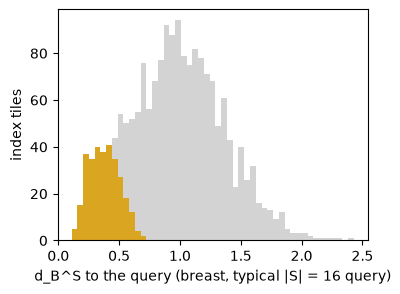

In [6]:
z = np.load(rio.topic(TOPIC) / "band" / "breast_cancer.npz")
bins = np.linspace(z["d"].min(), np.quantile(z["d"], 0.995), 50)
plt.figure(figsize=(4, 3))
plt.hist(z["d"], bins=bins, color="lightgrey")
plt.hist(z["d"][z["found"]], bins=bins, color="goldenrod")
plt.xlabel("d_B^S to the query (breast, typical |S| = 16 query)")
plt.ylabel("index tiles")
plt.show()

## Storage of the gene-set indexes and baselines

In [7]:
storage = gsa.storage_table()
rio.write_csv(storage, TOPIC, "storage.csv", "per dataset: MB (mean, s.d. over seeds, min, max) of whole covariances, "
              "Spindle-naive (gene sets), Spindle (gene sets), padding, imputation")
storage[["key", "whole", "naive_partial", "spindle_partial", "padding", "imputation",
         "spindle_partial_pct_naive_partial"]].round(2)

wrote results/gene_set/storage.csv: 8 rows


,key,whole,naive_partial,spindle_partial,padding,imputation,spindle_partial_pct_naive_partial
0,brain_cancer,4413.50,403.10,28.49,201.55,209.49,7.07
1,breast_cancer,361.68,57.01,3.90,28.50,29.25,6.85
2,kidney_nondiseased,200.93,22.52,1.61,11.26,11.89,7.16
3,lung_cancer,437.49,57.55,3.94,28.77,29.86,6.85
4,lymph_node,670.92,82.36,5.74,41.18,42.95,6.97
5,lymph_node_5k,2236.62,273.64,18.79,136.82,141.83,6.87
6,pancreatic_cancer,928.07,78.53,5.69,39.27,41.07,7.24
7,skin_melanoma,245.50,31.81,2.18,15.90,17.01,6.85


In [8]:
rio.write_manifest(TOPIC, "R3_gene_set.ipynb", inputs=["results/_cache"],
                   notes="Fig 4 accuracy and storage; the timing tables come from results/timing/gene_set.csv (R4)")

wrote results/gene_set/manifest.json: 61 files; peak memory 3.41 GB


{'topic': 'gene_set',
 'notebook': 'R3_gene_set.ipynb',
 'date': '2026-11-01 01:55',
 'tag': 'method-v2',
 'describe': 'method-v2-dirty',
 'commit': '8040f91',
 'inputs': ['results/_cache'],
 'peak_rss_gb': 3.41,
 'notes': 'Fig 4 accuracy and storage; the timing tables come from results/timing/gene_set.csv (R4)',
 'files': {'band/brain_cancer.npz': {'description': 'the typical |S| = 16 query (seed 0): exact d_B^S to every index tile (d), rows Spindle returned',
   'rows': None,
   'bytes': 38470},
  'band/breast_cancer.npz': {'description': 'the typical |S| = 16 query (seed 0): exact d_B^S to every index tile (d), rows Spindle returned',
   'rows': None,
   'bytes': 7990},
  'band/kidney_nondiseased.npz': {'description': 'the typical |S| = 16 query (seed 0): exact d_B^S to every index tile (d), rows Spindle returned',
   'rows': None,
   'bytes': 4182},
  'band/lung_cancer.npz': {'description': 'the typical |S| = 16 query (seed 0): exact d_B^S to every index tile (d), rows Spindle retu